In [2]:
import psycopg2
from psycopg2 import sql

db_params = {
            "database": "nlpdatabase",
            "user": "postgres",
            "password": "6487",
            "host": "localhost",
            "port": "5432",
        }

conn = psycopg2.connect(**db_params)

cursor = conn.cursor()

query = sql.SQL("""
            SELECT
                tr.body,
                ta.body,
                ml.similarity
            FROM
                matching_list ml
            JOIN releases re ON ml.id_releases = re.id 
            JOIN articles ar ON ml.id_articles = ar.id
            JOIN texts ta ON ta.id = ar.id_texts
            JOIN texts tr ON tr.id = re.id_texts
            WHERE re.language = 'PL' AND ar.language = 'PL'
        """)

cursor.execute(query)
rows = cursor.fetchall()

In [21]:
import psycopg2
from psycopg2 import sql

db_params = {
            "database": "nlpdatabase",
            "user": "postgres",
            "password": "6487",
            "host": "localhost",
            "port": "5432",
        }

conn = psycopg2.connect(**db_params)

cursor = conn.cursor()

query = sql.SQL("""
            SELECT
                tr.body
            FROM
                releases re
            JOIN texts tr ON tr.id = re.id_texts
            WHERE re.language = 'PL'
            UNION
            SELECT
                ta.body
            FROM
                articles ar
            JOIN texts ta ON ta.id = ar.id_texts
            WHERE ar.language = 'HR'
        """)

cursor.execute(query)
rows = cursor.fetchall()

In [22]:
len(rows)

384742

In [16]:
rows[0][0]

"'' Gužva '' - je poleg nevihte, neurja in nutrije najverjetneje najbolj pogosto izgovorjena beseda letošnjega poletja. O gužvi, tisti na cestah seveda, se govori povsod. Na televiziji, na radiju, v službi. Celo v naši počitniški vasi na jugu Istre, kamor v teh dneh periodično zahajam vsaj enkrat do dvakrat na teden, ne mine dan brez omembe gužve.\n\nDa smo Slovenci večinoma zaradi svoje lokalne omejenosti v smislu mobilnosti in premikov po naši deželi zelo razvajen narod je samoumevno. In kot kaže, se na poletno gnečo na naših avtocestah ne bomo nikoli navadili. Še manj možnosti pa je, da se bomo zategli kot smo, tej prometni tegobi znali prilagoditi. Po našem so krvi Nemci, Holandci, tudi Romuni in še posebej tovornjakarji.\n\nVendar je resnica, vsaj tista znana nam Ljubljančanom, drugačna. Gneča namreč že nekaj časa ni samo poletna tegoba, pač pa vsakodnevna stalnica našega obvoznega 'ringa' in prav tako tudi stalnica vsaj deset kilometrov daleč v vsak krak slovenskega avtocestnega 

In [18]:
def count_words(text):
    """
    Count the number of words in a given text.

    Parameters:
    - text (str): Input text.

    Returns:
    - int: Number of words in the text.
    """
    words = text.split()
    return len(words)

import matplotlib.pyplot as plt
import numpy as np

def create_histogram(data, threshold=700):
    """
    Create a histogram from a list of integers, ignoring values above a threshold.

    Parameters:
    - data (list of int): List of integers for the histogram.
    - threshold (int): Values above this threshold will be ignored in the histogram.

    Returns:
    - None
    """
    # Filter values below or equal to the threshold
    filtered_data = np.array(data)[np.array(data) <= threshold]
    
    plt.hist(filtered_data, bins=10, edgecolor='black')  # Adjust the number of bins as needed
    plt.xlabel('Values')
    plt.ylabel('Frequency')
    plt.title('Histogram')
    plt.show()

import statistics
def calculate_stats(float_list):
    if not float_list:
        print("List is empty.")
        return

    # Count 
    count = len(float_list)

    # Maximum
    max_value = max(float_list)

    # Minimum
    min_value = min(float_list)

    # Average
    avg_value = sum(float_list) / len(float_list)

    # Median
    median_value = statistics.median(float_list)

    # Variance
    variance_value = statistics.variance(float_list)

    # Standard Deviation
    std_deviation_value = statistics.stdev(float_list)

    # Print the results
    print(f"Count: {count}")
    print(f"Maximum: {max_value}")
    print(f"Minimum: {min_value}")
    print(f"Average: {avg_value:.2f}")
    print(f"Median: {median_value:.2f}")
    print(f"Variance: {variance_value:.2f}")
    print(f"Standard Deviation: {std_deviation_value:.2f}")

    return (max_value, min_value, avg_value, median_value, variance_value, std_deviation_value)

In [23]:
a = []

for i in range(len(rows)):
    b = count_words(rows[i][0])
    a.append(b)

In [20]:
calculate_stats(a)

Count: 168405
Maximum: 14713
Minimum: 13
Average: 360.15
Median: 273.00
Variance: 115886.53
Standard Deviation: 340.42


(14713, 13, 360.1477153291173, 273, 115886.52669433905, 340.4211020109345)

11219

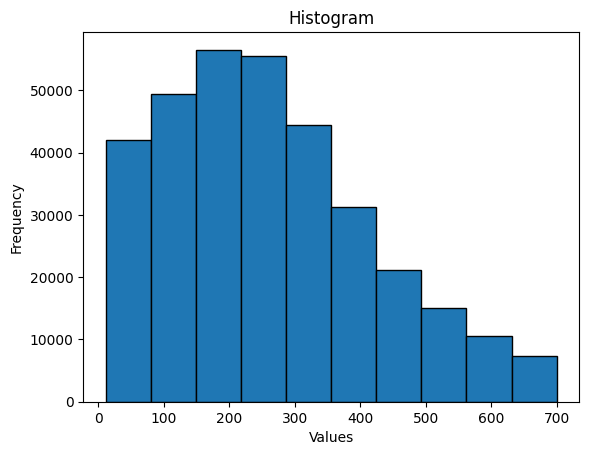

In [14]:
create_histogram(a)

In [8]:
import statistics
def calculate_stats(float_list):
    if not float_list:
        print("List is empty.")
        return

    # Maximum
    max_value = max(float_list)

    # Minimum
    min_value = min(float_list)

    # Average
    avg_value = sum(float_list) / len(float_list)

    # Median
    median_value = statistics.median(float_list)

    # Variance
    variance_value = statistics.variance(float_list)

    # Standard Deviation
    std_deviation_value = statistics.stdev(float_list)

    # Print the results
    print(f"Maximum: {max_value}")
    print(f"Minimum: {min_value}")
    print(f"Average: {avg_value:.2f}")
    print(f"Median: {median_value:.2f}")
    print(f"Variance: {variance_value:.2f}")
    print(f"Standard Deviation: {std_deviation_value:.2f}")

    return (max_value, min_value, avg_value, median_value, variance_value, std_deviation_value)